In [3]:

# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow.keras import layers
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import Adam

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score


In [5]:
# load the Dataset

df = pd.read_csv("/content/nvda_stock.csv")

In [6]:
df

,Date,Open,High,Low,Close,Volume
0,2010-01-04,0.424242,0.426763,0.415074,0.423784,800204000
1,2010-01-05,0.422179,0.434556,0.422179,0.429972,728648000
2,2010-01-06,0.429743,0.433639,0.425617,0.432722,649168000
3,2010-01-07,0.430430,0.432264,0.421033,0.424242,547792000
4,2010-01-08,0.420804,0.428139,0.418283,0.425159,478168000
...,...,...,...,...,...,...
4103,2026-04-28,209.490005,214.729996,208.199997,213.169998,180275400
4104,2026-04-29,212.699997,212.720001,207.580002,209.250000,123711800
4105,2026-04-30,209.929993,210.300003,198.699997,199.570007,225239200
4106,2026-05-01,201.279999,203.000000,197.119995,198.449997,128647000


In [7]:
# step 3 Exploration Data

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4108 entries, 0 to 4107
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Date    4108 non-null   object 
 1   Open    4108 non-null   float64
 2   High    4108 non-null   float64
 3   Low     4108 non-null   float64
 4   Close   4108 non-null   float64
 5   Volume  4108 non-null   int64  
dtypes: float64(4), int64(1), object(1)
memory usage: 192.7+ KB


In [8]:
# check the outliers

df.describe()

,Open,High,Low,Close,Volume
count,4108.000000,4108.000000,4108.000000,4108.000000,4.108000e+03
mean,26.024894,26.451211,25.552379,26.021081,4.735287e+08
std,49.394800,50.128682,48.547739,49.364617,3.051482e+08
min,0.199859,0.207423,0.198255,0.203526,4.564400e+07
25%,0.434635,0.440246,0.428689,0.434418,2.774374e+08
50%,4.114192,4.168928,4.059048,4.104808,4.043840e+08
75%,19.244044,19.592118,18.803971,19.263086,5.809790e+08
max,212.699997,216.830002,208.199997,216.610001,3.692928e+09


In [9]:
# Drop the date column
df.drop("Date", axis = 1, inplace = True)

In [10]:
# Handle the outliers

outliers_column = ["Open", "High", "Low", "Volume"]

for column in outliers_column:
  #find the Q1 and Q3

  Q1 = df[column].quantile(0.25)
  Q3 = df[column].quantile(0.75)

  # calculate the IQR

  IQR = Q3 - Q1

  #find the lower and upper bound

  upper_bound = Q3 + 1.5 * IQR
  Lower_bound = Q1 - 1.5 * IQR

  # handle the outlier using clipling

  df[column] = df[column].clip(Lower_bound, upper_bound)

In [11]:
# step 4 divide the data into X and y variables
X = df.drop("Close", axis =1 )
y = df["Close"]


In [12]:
# step 5 Scale the data

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

In [13]:
# step 6 split the dataset into the train and test part

X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

In [14]:
# step 7 : Model building

model = Sequential()

# first hidden layer
model.add(Dense(64, activation="relu", input_shape=(X_train.shape[1],)))

# second hidden layer
model.add(Dense(32, activation="relu"))

# third hidden layer
model.add(Dense(16, activation = "relu"))

#forth hidden layer
model.add(Dense(8, activation = "relu"))

# fifth hidden layer
model.add(Dense(1))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [15]:
# model summary

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,073 (12.00 KB)

 Trainable params: 3,073 (12.00 KB)

 Non-trainable params: 0 (0.00 B)

In [16]:
from sklearn import metrics
# model compile

model.compile(optimizer=Adam(learning_rate=0.001),loss='mean_squared_error',metrics=["r2_score"])

In [17]:
# train the model

model.fit(X_train, y_train,validation_data=(X_test,y_test),epochs=30,verbose=True)

Epoch 1/30
103/103 ━━━━━━━━━━━━━━━━━━━━ 7s 36ms/step - loss: 2529.1353 - r2_score: -0.0428 - val_loss: 986.2203 - val_r2_score: 0.6023
Epoch 2/30
103/103 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 428.1855 - r2_score: 0.8235 - val_loss: 363.8549 - val_r2_score: 0.8533
Epoch 3/30
103/103 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 304.1235 - r2_score: 0.8746 - val_loss: 285.4568 - val_r2_score: 0.8849
Epoch 4/30
103/103 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 230.4956 - r2_score: 0.9050 - val_loss: 232.9373 - val_r2_score: 0.9061
Epoch 5/30
103/103 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 181.1327 - r2_score: 0.9253 - val_loss: 192.7511 - val_r2_score: 0.9223
Epoch 6/30
103/103 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 159.0175 - r2_score: 0.9344 - val_loss: 181.9828 - val_r2_score: 0.9266
Epoch 7/30
103/103 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 147.1650 - r2_score: 0.9393 - val_loss: 177.0149 - val_r2_score: 0.9286
Epoch 8/30
103/103 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 146.9306 - r2

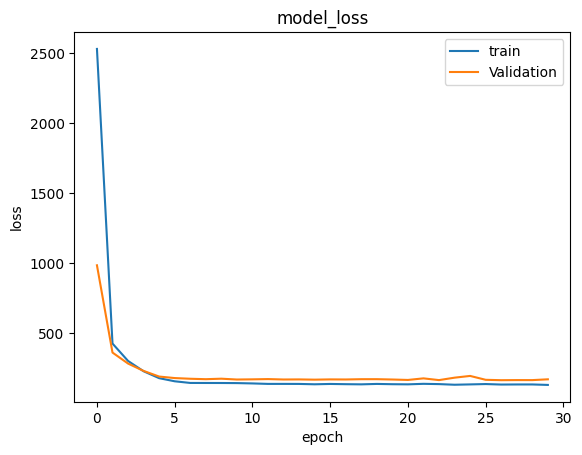

In [18]:
# check the loss plot
plt.plot(model.history.history["loss"])
plt.plot(model.history.history["val_loss"])
plt.title("model_loss")
plt.ylabel("loss")
plt.xlabel("epoch")
plt.legend(["train","Validation"], loc="upper right")
plt.show()